# Librerías 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Preprocesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Selección de características
from sklearn.feature_selection import SequentialFeatureSelector

# Reducción de dimensionalidad
from sklearn.decomposition import PCA

# Model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# Métricas
from sklearn.metrics import accuracy_score, classification_report, recall_score, roc_auc_score, roc_curve, auc, confusion_matrix, f1_score

# Pipelines y balanceo
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

--------------------------------------
# Carga dataset para exploración 

In [2]:
churn = pd.read_excel("DATA.xlsx")
churn

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


Lo primero que vamos a hacer es dividir el dataset en train y test y hacer el EDA con el conjunto de train simulando el escenario real en el que los datos de test no los tenemos y lo que tenemos para trabajar son únicamente los datos de train. 
Posteriormente todas las transformaciones que hemos hecho en train las vamos a meter en una funcion y se la vamos a aplicar al conjunto de test y vamos a guardar ambos datasets limpios para tener mejor reproducibilidad y solo tener que importarlos sin necesidad de ejecutar la limpieza siempre.

In [3]:
X = churn.drop(columns='Churn Value')
Y = churn['Churn Value']

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,shuffle=True, stratify=Y,random_state=10)
churn = X_train
churn['Churn Value'] = Y_train


#Ahora nos guardamos el de test que pasaremos luego a una funcion para impiarlo y descargarlo a parte del conjunto de train limpio.
churntest = X_test
churntest['Churn Value'] = Y_test

In [4]:
print(churn.shape)

(5282, 33)


--------------------------------------------
# Análisis de tipos de dato

In [5]:
churn.dtypes

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Score            int64
CLTV                   int64
Churn Reason          object
Churn Value            int64
dtype: object


La columna total Charges debería ser de tipo float, el problema es que si cambiamos el tipo da el siguiente error:


ValueError: could not convert string to float: ' '

Eso significa que hay espacios que imposibilitan el cambio de tipo al float, por ello reemplazaremos los espacios por na y luego los analizaremos


In [6]:
espacios_en_blanco = churn[churn['Total Charges'] == ' ']
espacios_en_blanco

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Score,CLTV,Churn Reason,Churn Value
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,,No,69,4890,NaN,0
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,,No,30,4740,NaN,0
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,,No,53,2019,NaN,0
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,,No,36,2578,NaN,0
6840,2775-SEFEE,1,United States,California,Wilmington,90744,"33.782068, -118.262263",33.782068,-118.262263,Male,...,Two year,Yes,Bank transfer (automatic),61.90,,No,65,5188,NaN,0
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,,No,27,3763,NaN,0
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,,No,45,2048,NaN,0
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,,No,49,2299,NaN,0
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,,No,48,4950,NaN,0


In [7]:
churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)

# Convierte la columna a float. Ahora ya no dará error.
churn['Total Charges'] = churn['Total Charges'].astype(float)

C:\Users\jorge\AppData\Local\Temp\ipykernel_2860\3810830123.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)


------------------
# Análisis de nulls

In [8]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5282 entries, 3069 to 1344
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         5282 non-null   object 
 1   Count              5282 non-null   int64  
 2   Country            5282 non-null   object 
 3   State              5282 non-null   object 
 4   City               5282 non-null   object 
 5   Zip Code           5282 non-null   int64  
 6   Lat Long           5282 non-null   object 
 7   Latitude           5282 non-null   float64
 8   Longitude          5282 non-null   float64
 9   Gender             5282 non-null   object 
 10  Senior Citizen     5282 non-null   object 
 11  Partner            5282 non-null   object 
 12  Dependents         5282 non-null   object 
 13  Tenure Months      5282 non-null   int64  
 14  Phone Service      5282 non-null   object 
 15  Multiple Lines     5282 non-null   object 
 16  Internet Service   5282 no

In [9]:
print(churn['Churn Value'].value_counts())

Churn Value
0    3880
1    1402
Name: count, dtype: int64


Si nos fijamos bien se ve que todas las columnas tienen todos los valores no nulos excepto 'Churn Reason' (la última). Esto tiene sentido porque como podemos comprobar 1402 es el número de valores no nulos y se corresponde con el número de filas que tienen valor 1 (abandono), así que tiene sentido. Vamos a sustituir los nulos entonces por el valor 'se_queda'.  

In [10]:
churn['Churn Reason'] = churn['Churn Reason'].fillna('se_queda')

In [11]:
churn['Churn Reason'].isna().sum()
print(churn["Churn Reason"].value_counts())

Churn Reason
se_queda                                     3880
Competitor offered higher download speeds     153
Attitude of support person                    144
Competitor offered more data                  124
Don't know                                    106
Attitude of service provider                  105
Competitor made better offer                  101
Competitor had better devices                  98
Product dissatisfaction                        75
Price too high                                 75
Network reliability                            74
Service dissatisfaction                        68
Lack of self-service on Website                64
Moved                                          41
Extra data charges                             39
Lack of affordable download/upload speed       37
Limited range of services                      34
Long distance charges                          33
Poor expertise of phone support                16
Poor expertise of online support     

Para atribuir los nulls a la columna de Total Charges primero vamos a ver como se distribuyen sus datos

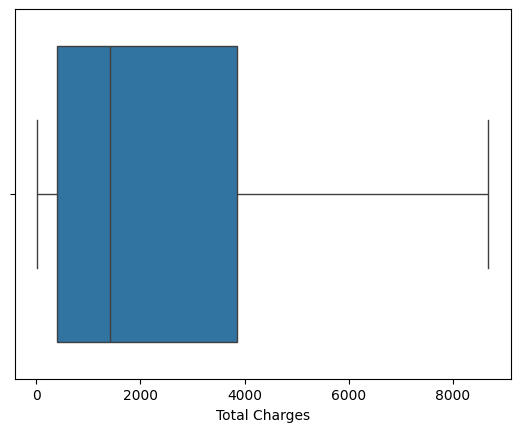

In [12]:
sns.boxplot(data = churn, x=churn['Total Charges'])
plt.show()

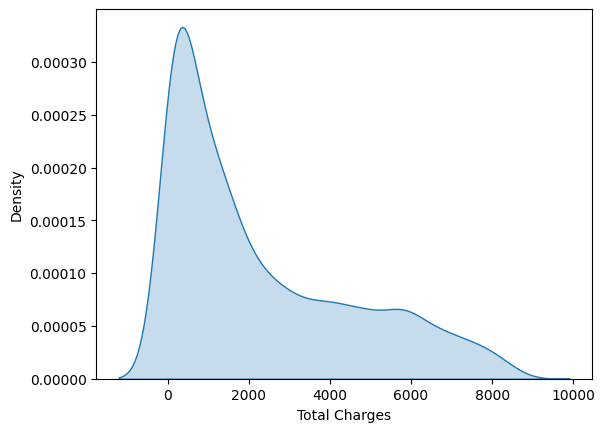

In [13]:
sns.kdeplot(data = churn, x = 'Total Charges', fill = True)
plt.show()

In [14]:
print(churn['Total Charges'].describe())

count    5273.000000
mean     2295.693818
std      2278.435269
min        18.850000
25%       400.000000
50%      1411.650000
75%      3846.350000
max      8684.800000
Name: Total Charges, dtype: float64


Como se puede ver gracias al .describe() y al kdeplot, la media se ve afectada por unos valores altos que estan sesgando la distribución entonces es mejor aplicar la mediana.

In [15]:
mediana_cargos = churn['Total Charges'].median()

In [16]:
churn['Total Charges'].fillna(mediana_cargos, inplace=True)

C:\Users\jorge\AppData\Local\Temp\ipykernel_2860\4195289185.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  churn['Total Charges'].fillna(mediana_cargos, inplace=True)


---------------------------------------------

# Comprobación de valores duplicados

In [17]:
churn[churn['CustomerID'].duplicated()]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Score,CLTV,Churn Reason,Churn Value


Hemos comprobado que no hay duplicados en la única columna que tiene sentido que no haya dulpicados, CustomerID

------------------------------------------------------------------------

# Eliminación de columnas innecesarias

In [18]:
print('Países diferentes:')
print(churn['Country'].unique())
print('Estados diferentes:')
print(churn['State'].unique())
print('Ciudades diferentes:')
print(churn['City'].nunique())

Países diferentes:
['United States']
Estados diferentes:
['California']
Ciudades diferentes:
1121


Podemos usar las columnas geográficas para analizar si hay diferencias entre regiones, sin embargo realmente solo es útil la de "City", porque la columna de 'State' tiene únicamente el valor "California", la de 'Country' solo tiene el valor "Estados Unidos". La de 'Count' tampoco es muy útil porque suponiendo que el dataset tiene sentido y cada cliente es único el valor va a ser 1 nos podemos quedar directamente con CustomerID.

In [19]:
churn = churn.drop(columns = ['Count','State','Country','Zip Code', 'Lat Long','Latitude','Longitude'])

------------
# Comprobación outliers y valores sin sentido

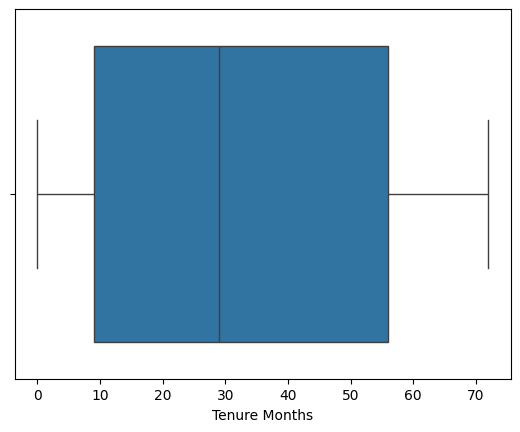

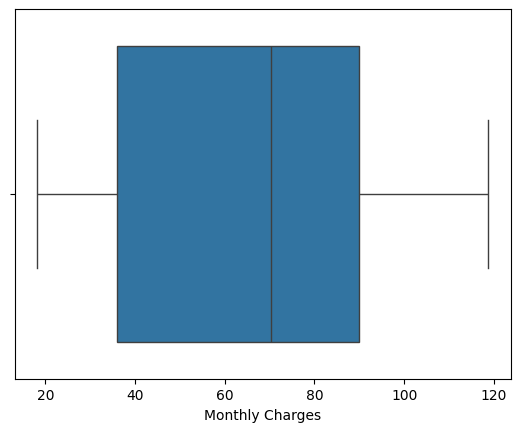

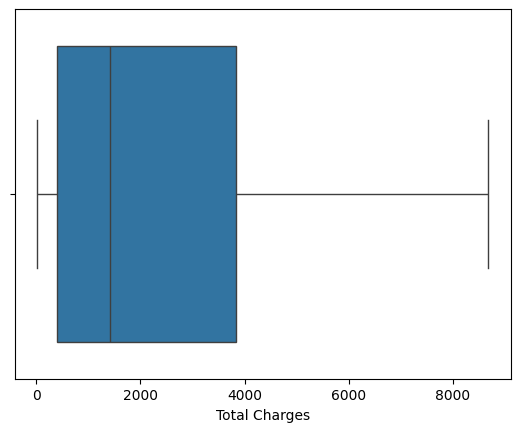

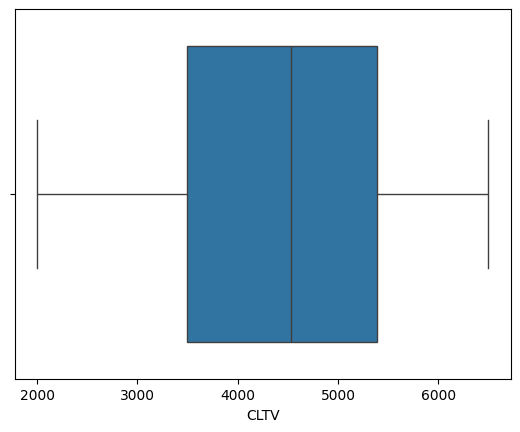

In [20]:
lista_columnas_outliers = ['Tenure Months','Monthly Charges','Total Charges','CLTV']
for n in lista_columnas_outliers:
    sns.boxplot(data = churn, x = churn[n])
    plt.show()

In [21]:
for n in lista_columnas_outliers:
    print(churn[n].describe())
    print('----------------')

count    5282.000000
mean       32.489019
std        24.649445
min         0.000000
25%         9.000000
50%        29.000000
75%        56.000000
max        72.000000
Name: Tenure Months, dtype: float64
----------------
count    5282.000000
mean       64.935735
std        30.102860
min        18.250000
25%        35.900000
50%        70.350000
75%        89.950000
max       118.750000
Name: Monthly Charges, dtype: float64
----------------
count    5282.000000
mean     2294.187495
std      2276.784978
min        18.850000
25%       401.200000
50%      1411.650000
75%      3838.612500
max      8684.800000
Name: Total Charges, dtype: float64
----------------
count    5282.000000
mean     4408.440742
std      1182.435221
min      2003.000000
25%      3491.000000
50%      4534.500000
75%      5389.500000
max      6499.000000
Name: CLTV, dtype: float64
----------------


Aparentemente no tenemos outliers en las columnas numéricas.

In [22]:
# Nos hemos dado cuenta de que según la descripción del dataset hay columnas que únicamente deberían tienen el valor SI/NO, sin embargo al hacer los histogramas por columnas más abajo hemos encontrado 
# valores que no deberían tener como 'No phone service" y "No internet service" (que básicamente significan "NO"), por ello los vamos a reemplazar a continuación por "No" con un bucle. 

churn["Multiple Lines"] =  churn["Multiple Lines"].replace("No phone service", "No")
churn["Multiple Lines"].value_counts()

columnas_a_transformar_a_no = [
    'Streaming Movies','Streaming TV',
    'Tech Support', 'Device Protection'
    ,'Online Backup', 'Online Security']
for columna in columnas_a_transformar_a_no:
    churn[columna] = churn[columna].replace("No internet service", "No")
    print(f"la columna: '{columna}' \ntiene ahora estos tipos: \n '{churn[columna].value_counts()}'\n")

la columna: 'Streaming Movies' 
tiene ahora estos tipos: 
 'Streaming Movies
No     3241
Yes    2041
Name: count, dtype: int64'

la columna: 'Streaming TV' 
tiene ahora estos tipos: 
 'Streaming TV
No     3238
Yes    2044
Name: count, dtype: int64'

la columna: 'Tech Support' 
tiene ahora estos tipos: 
 'Tech Support
No     3730
Yes    1552
Name: count, dtype: int64'

la columna: 'Device Protection' 
tiene ahora estos tipos: 
 'Device Protection
No     3448
Yes    1834
Name: count, dtype: int64'

la columna: 'Online Backup' 
tiene ahora estos tipos: 
 'Online Backup
No     3443
Yes    1839
Name: count, dtype: int64'

la columna: 'Online Security' 
tiene ahora estos tipos: 
 'Online Security
No     3747
Yes    1535
Name: count, dtype: int64'



-------
# Análisis de patrones 

Este apartado del EDA nos parece especialmente importante porque si bien aplicando algoritmos variados de machine learning podemos encontrar soluciones avanzadas, a veces con un simple histograma o un gráfico de barras podemos encontrar patrones de los datos y proponer soluciones simples que podrían tener igual o más impacto en el éxito del negocio (que al fin y al cabo es el objetivo final).

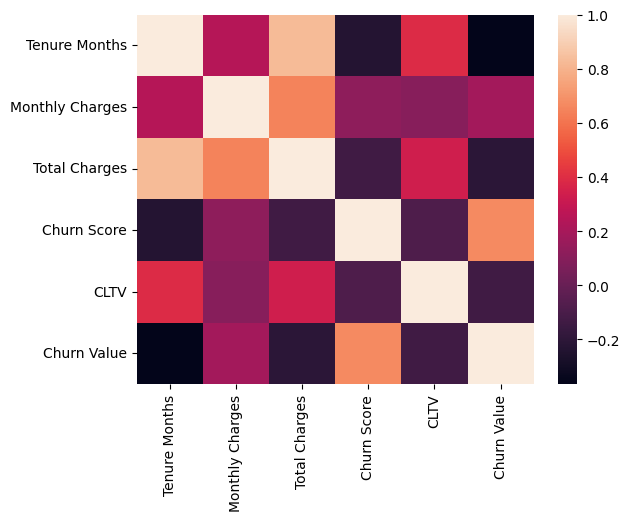

In [23]:
corr = churn.corr(numeric_only=True)
sns.heatmap(data = corr)
plt.show()

Tenure months correlaciona negativamente con el churn value y el churn score, puede significar que a menor cantidad de meses en la compañía los clientes tienen mayor probabilidad de irse y viceversa. Además correlaciona positivamente con el CLTV, lo que es lógico porque cuanto más tiempo con la compañía más dinero gasta y más valor tiene para ella. 

Churn Value
0    0.73457
1    0.26543
Name: proportion, dtype: float64


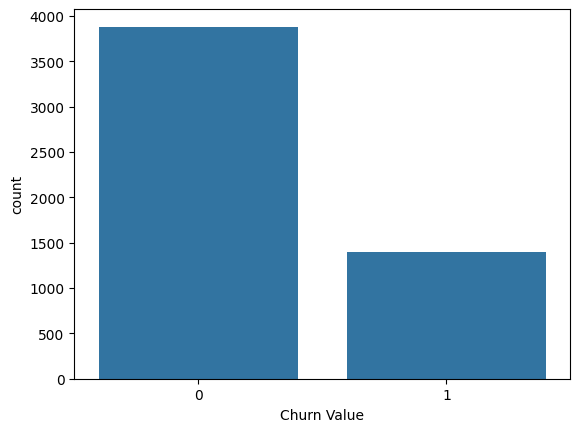

In [24]:
print(churn['Churn Value'].value_counts(normalize=True))

sns.countplot(data = churn, x = churn['Churn Value'])
plt.show()

Contamos con un 26% de clientes que abandonan frente a un 73% que no abandona en el dataset, esto puede tener mayor relevancia luego para los conjuntos de entrenamiento y test. Conviene evaluar el desempeño de los modelos con estratificación. 

In [25]:
filtro_se_van = churn[churn['Churn Value']==1]
lista_razones_abandono = list(filtro_se_van['Churn Reason'].unique())
print(f'Hay en total {len(lista_razones_abandono)} razones diferentes de abandono:\n')
# Se ha hecho el filtro para que no se incluya en el bucle 'se_queda' correspondiente a los que no se han ido

numero = 1
for n in lista_razones_abandono:
    print(f'{numero} - {n}')
    numero = numero +1

Hay en total 20 razones diferentes de abandono:

1 - Attitude of support person
2 - Moved
3 - Competitor offered more data
4 - Product dissatisfaction
5 - Lack of affordable download/upload speed
6 - Attitude of service provider
7 - Lack of self-service on Website
8 - Network reliability
9 - Competitor made better offer
10 - Competitor had better devices
11 - Competitor offered higher download speeds
12 - Extra data charges
13 - Don't know
14 - Service dissatisfaction
15 - Long distance charges
16 - Price too high
17 - Poor expertise of phone support
18 - Limited range of services
19 - Deceased
20 - Poor expertise of online support


In [26]:
agrupacion = filtro_se_van.groupby('Churn Reason').agg(recuento = ('CustomerID', 'count')).nlargest(10,columns='recuento').reset_index()
agrupacion

,Churn Reason,recuento
0,Competitor offered higher download speeds,153
1,Attitude of support person,144
2,Competitor offered more data,124
3,Don't know,106
4,Attitude of service provider,105
5,Competitor made better offer,101
6,Competitor had better devices,98
7,Price too high,75
8,Product dissatisfaction,75
9,Network reliability,74


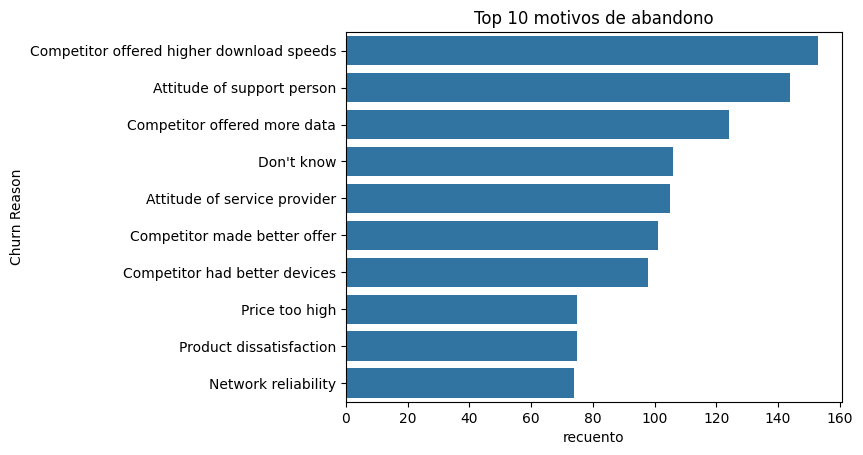

In [27]:
sns.barplot(data = agrupacion, y = 'Churn Reason', x = 'recuento')
plt.title('Top 10 motivos de abandono')
plt.show()

En el gráfico de top 10 de motivos principales de abandono encontramos como principal la actitud de la persona de atención de atención al cliente (lo cual puede indicar un área importante a mejorar o a tomar medidas) y además tres de las cinco principales razones están relacionadas con prestaciones de la competencia, lo que puede indicar puntos débiles de la compañía. 

In [28]:
recuento_ciudades_con_mas_clientes = churn.groupby(['City']).agg(recuento_clientes = ('CustomerID', 'count')).reset_index().nlargest(20,columns='recuento_clientes')
lista_ciudades = list(recuento_ciudades_con_mas_clientes['City'].unique())
recuento_ciudades_con_mas_clientes

,City,recuento_clientes
560,Los Angeles,239
865,San Diego,109
874,San Jose,86
868,San Francisco,83
851,Sacramento,81
353,Fresno,50
554,Long Beach,44
699,Oakland,41
56,Bakersfield,32
370,Glendale,32


In [29]:
churn_grafico = churn[churn['City'].isin(lista_ciudades)]

Análisis de los clientes que se van y se quedan de las 30 ciudades con mas clientes

<Axes: xlabel='count', ylabel='City'>

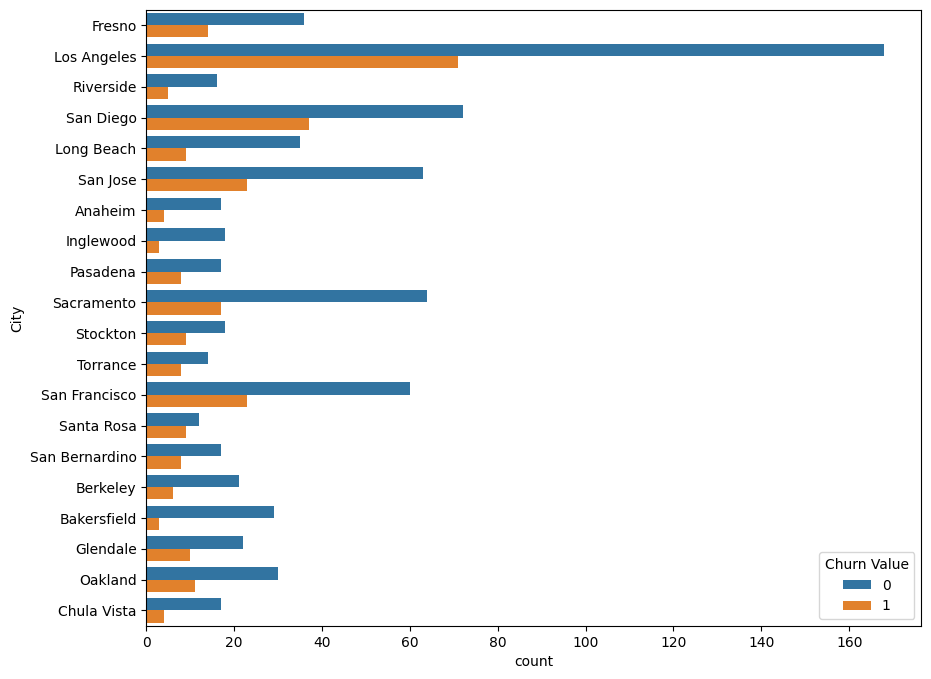

In [30]:
plt.figure(figsize = (10,8))
sns.countplot(data = churn_grafico, y = 'City', hue='Churn Value')
# plt.xticks(rotation = 45)

 El  gráfico  muestra que las ciudades con más clientes (Los Ángeles, San Diego, San José, Sacramento y San Francisco) son también las que tienen más abandonos, simplemente  por cantidad de población. En todas las ciudades hay más clientes que se quedan que clientes que se van, pero algunas como San Diego o Los Ángeles destacan por tener un alto número de bajas. A continuación, calcularemos qué ciudades tienen más proporción de gente que se va.

Análisis de la proporción de abandono dentro de las 20 ciudades con mas clientes 

In [31]:
total = churn.groupby('City').agg(total = ('CustomerID','count')).reset_index()
total

,City,total
0,Acampo,3
1,Acton,2
2,Adelanto,4
3,Adin,1
4,Agoura Hills,4
...,...,...
1116,Yountville,2
1117,Yuba City,4
1118,Yucaipa,4
1119,Yucca Valley,4


In [32]:
clientes_que_se_van = churn[churn['Churn Value'] == 1]

In [33]:
agrupacion_Se_van = clientes_que_se_van.groupby('City').agg(se_van = ('CustomerID','count')).reset_index()
total
agrupacion_Se_van

,City,se_van
0,Acampo,2
1,Adin,1
2,Agoura Hills,2
3,Aguanga,1
4,Ahwahnee,1
...,...,...
714,Yorba Linda,1
715,Yosemite National Park,2
716,Yuba City,1
717,Yucaipa,1


In [34]:
total = total.merge(agrupacion_Se_van, how = 'left',left_on='City', right_on = 'City')
total['proporcion'] = (total['se_van']/total['total']) * 100


In [35]:
total = total[total['City'].isin(lista_ciudades)].sort_values(by='proporcion',ascending = False)

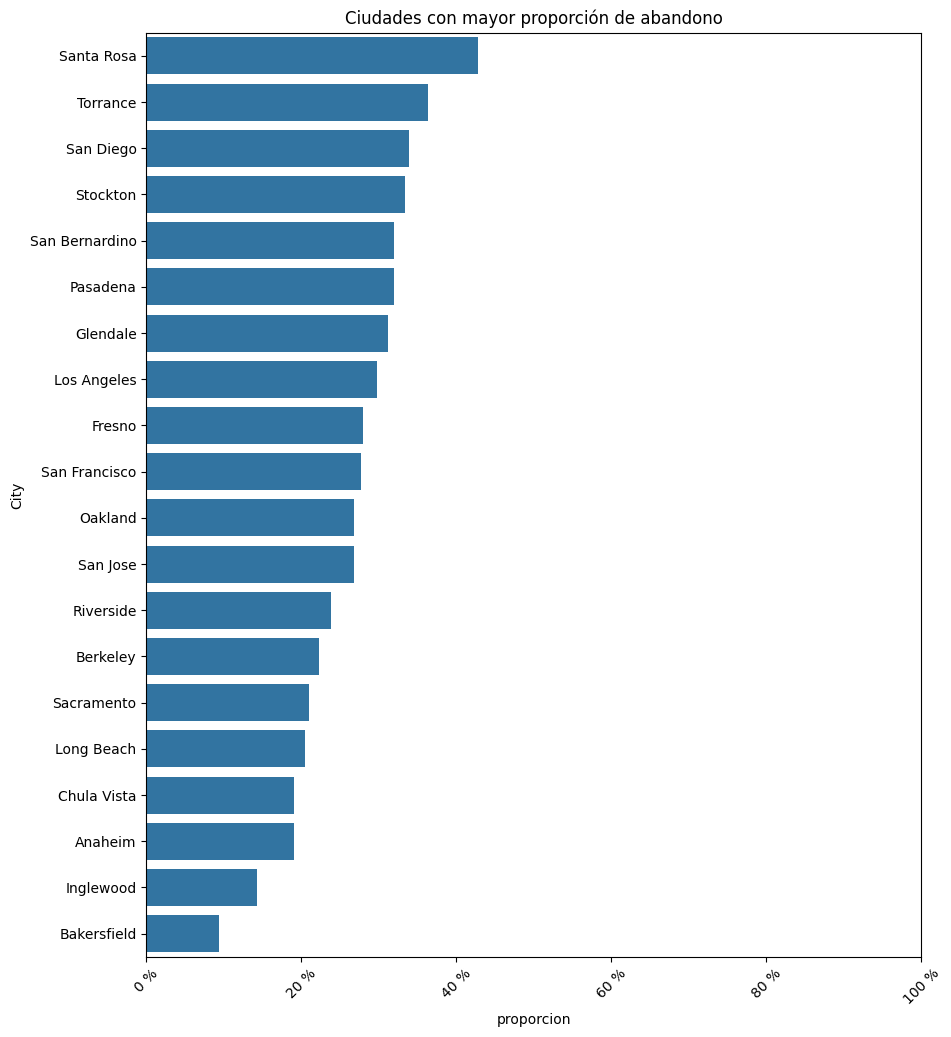

In [36]:
plt.figure(figsize = (10,12))
sns.barplot(data = total, x = 'proporcion', y='City', estimator='sum')
plt.title('Ciudades con mayor proporción de abandono')
plt.xticks([0, 20, 40, 60, 80, 100])
plt.gca().set_xticklabels(["0 %", "20 %", "40 %", "60 %", "80 %", "100 %"])
plt.xticks(rotation = 45)
plt.show()

El gráfico muestra qué ciudades tienen  mayor proporción de clientes que abandonan. Modesto y Santa Bárbara son las que presentan mayor proporción. En estas ciudades el riesgo de abandono es claramente superior a la media. Este análisis representa donded está realmente concentrado el problema del churn, independientemente del tamaño de cada ciudad

In [37]:
columas_para_histograma = ['Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges','Churn Score', 'CLTV']

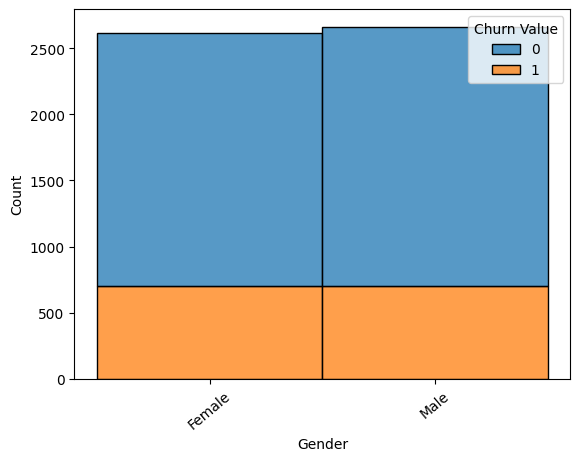

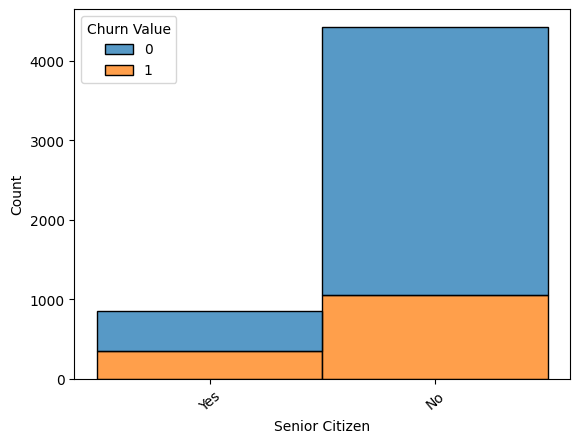

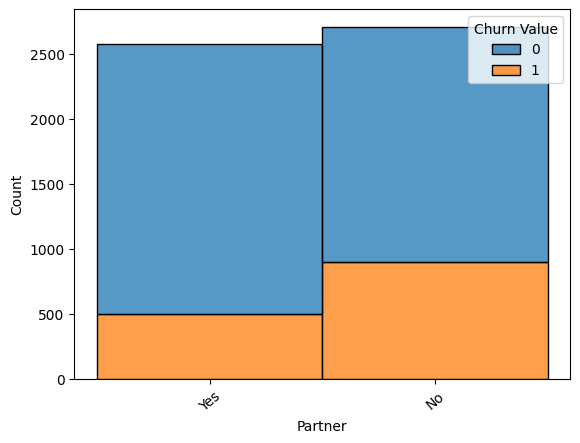

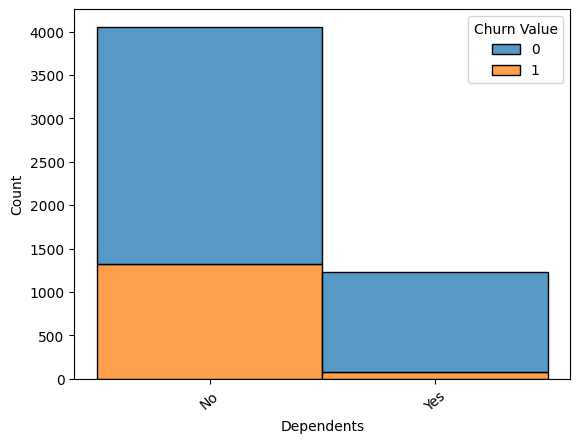

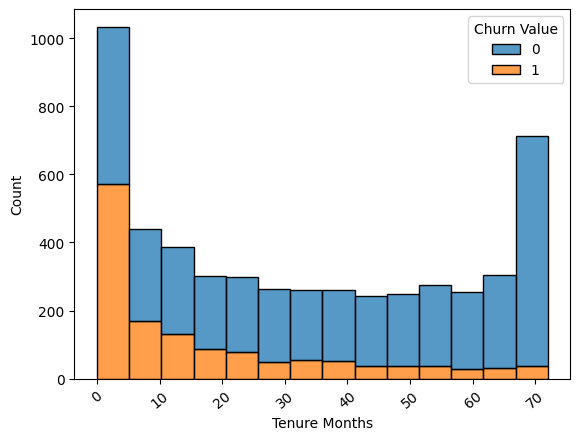

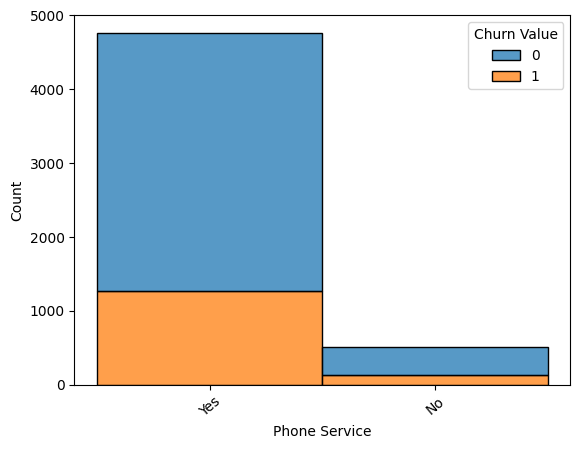

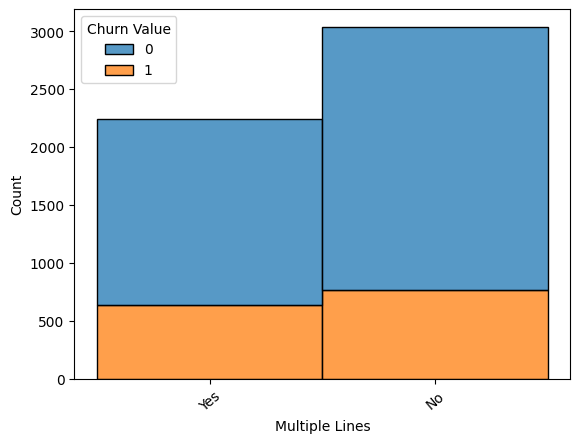

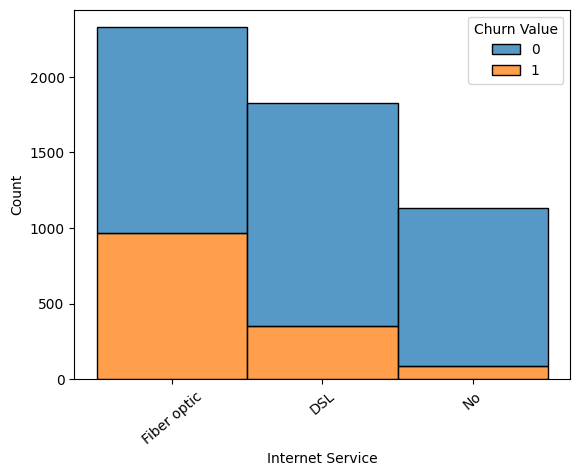

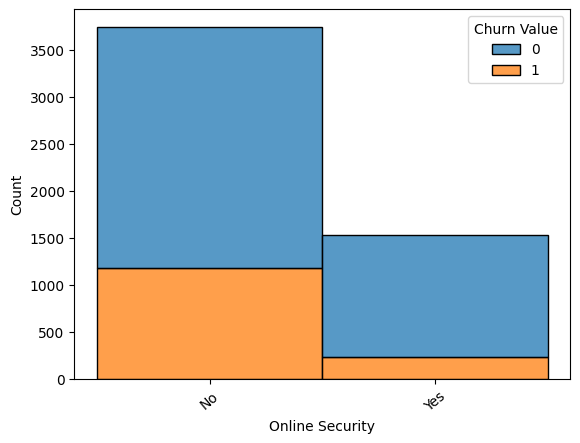

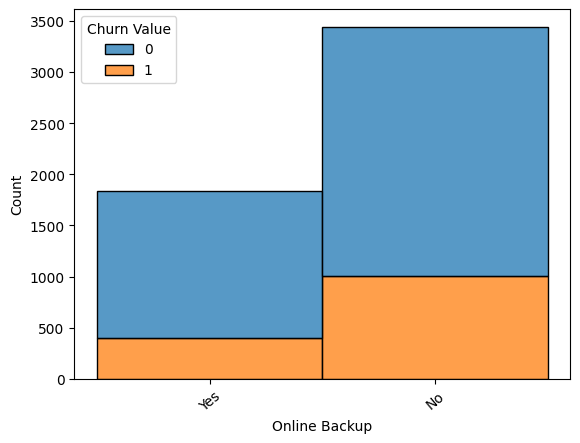

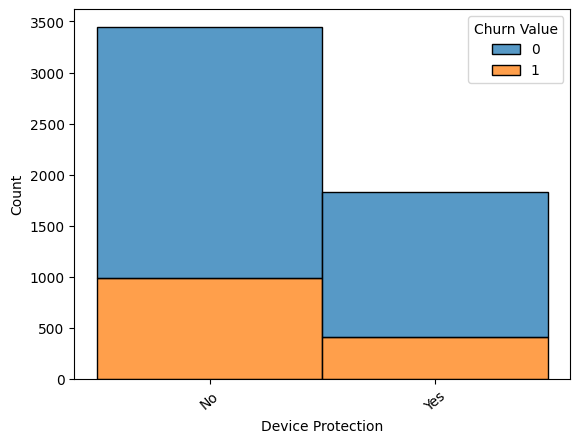

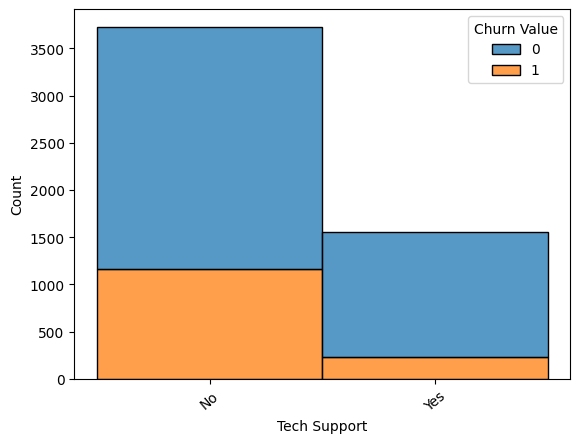

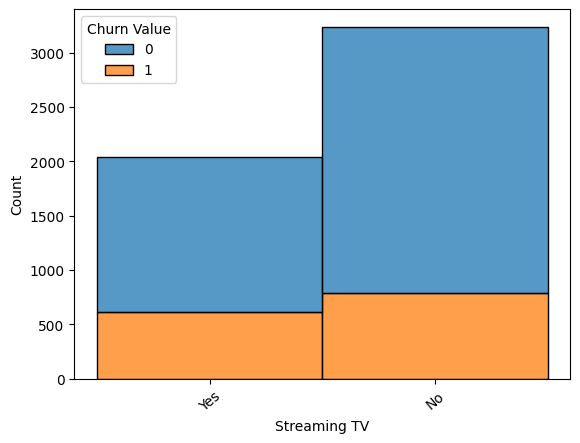

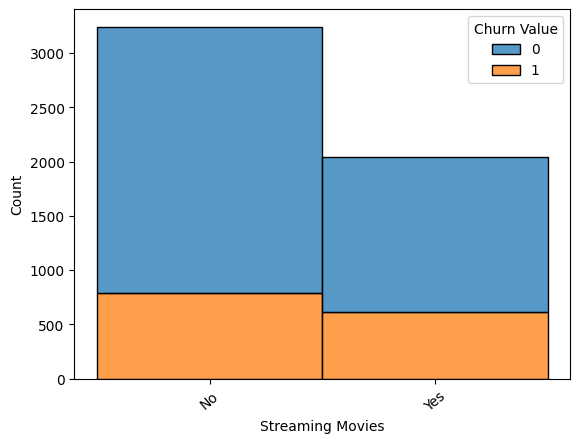

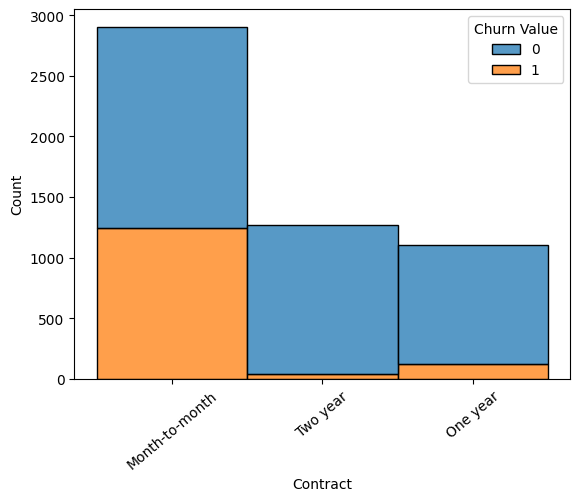

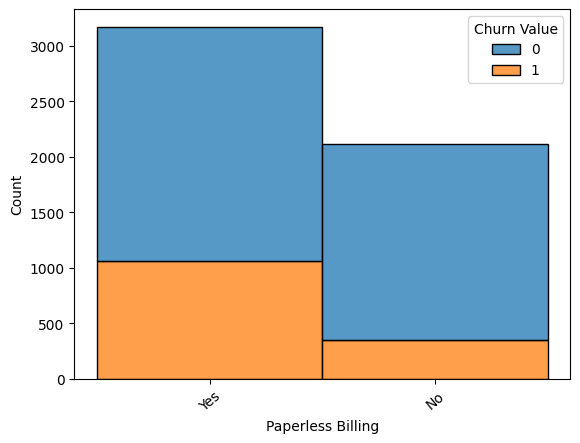

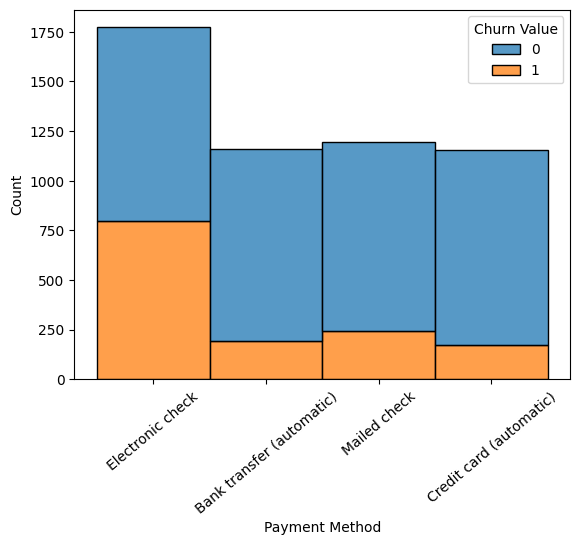

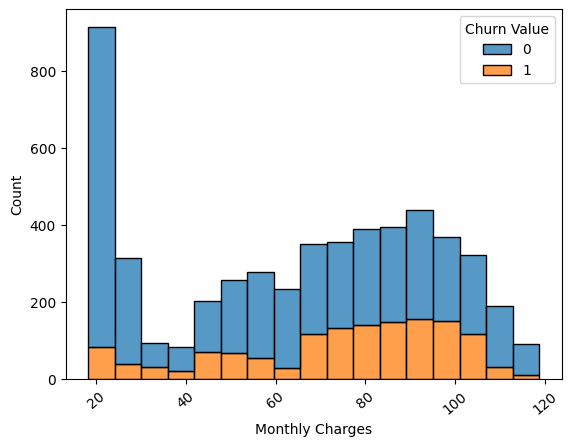

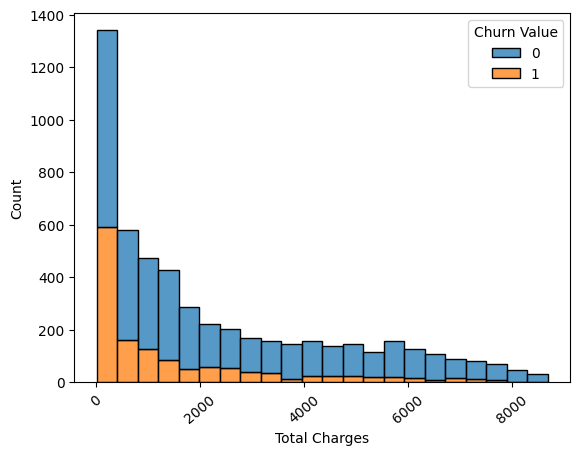

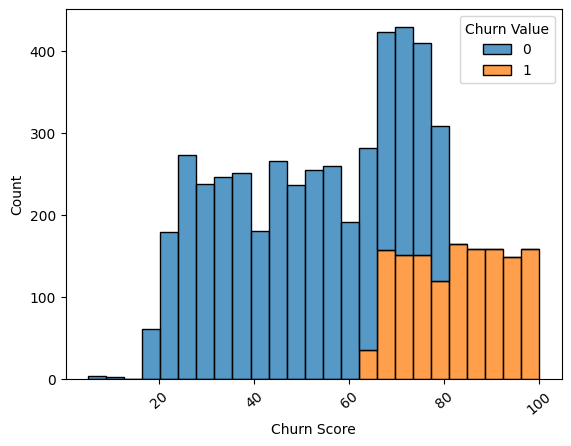

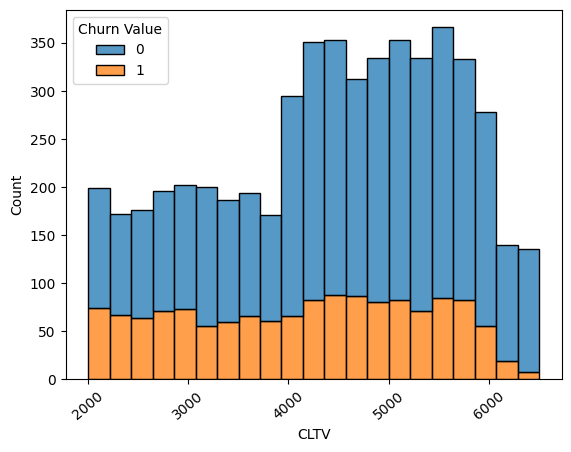

In [38]:
for n in columas_para_histograma:
    sns.histplot(data = churn, x = n, hue = churn['Churn Value'],multiple="stack")
    plt.xticks(rotation = 40)
    plt.show()

Los gráficos muestran que el churn es en proporción más común en clientes mayores, sin pareja , sin dependientes, y en personas que llevan poco tiempo en la empresa.  Los usuarios que no contratan servicios adicionales también presentan tasas de abandono más altas.

En cuanto al servicio, los clientes con interrnet muestran más probabilidades de irse. Además, el tipo de contrato es clave, ya que los clientes con el month-to-month contract son los que más abandonan la empresa, mientras que los contratos anuales retienen mucho mejor a los clientees. También se observa un mayor churn entre quienes usan facturación electrónica y pagan con electronic check. Además en el histograma del tipo de servicio de internet contratado se observa que la proporción de los clientes que abandonan es especialmente alta para los que contratan fibra óptica, lo que puede indicar un punto débil de la compañía o fuerte de la competencia.

En cuanto a los clientes con cuotas mensuales altas, estos abandonan más, mientras que los que tienen total charges bajos suelen corresponder a clientes nuevos que se marchan pronto. 

Por último, el churn score y el CLTV confirman que los clientes con scoring alto y valor medio-alto presentan un mayor riesgo de abandono.

-----
# Plan de acción basado en los patrones encontrados:

* Programa Onboarding inicial: Para mitigar el alto riesgo de abandono (churn) en los clientes con baja antigüedad (Tenure Months), es fundamental transformar la fase inicial del cliente para garantizar una experiencia inicial fluida y resolver proactivamente cualquier fricción o duda a través de un seguimiento de alto contacto  y con posibles incentivos de permanencia como "hitos semestrales" que favorezcan la fidelización y la estancia a largo plazo.

* Auditoría de atención al cliente: El hecho de que la principal razón de abandono esté relacionada con la atención al cliente es preocupante por lo que conviene llevar a cabo una auditoría en este departamento que pase por realizar grabaciones y analizar las interacciones de atención al cliente y llevar a cabo una capacitación intensiva al personal. Invertir en coaching centrado en habilidades blandas como empatía, o resolución de conflictos y habilidades técnicas para asegurar que el personal de soporte sea capaz de solucionar los problemas de los clientes. Además sería conveniente implementar métricas de satisfacción como encuestas post-interacción.

* Monitoreo Prioritario: Utilizar el churn score para crear una lista de clientes de alto valor (CLTV) con alto riesgo de abandono y asignar a estos clientes a un equipo de retención especializado con ofertas de fidelización superiores. Además la proporción de personas mayores que abandonan frente a la proporción de mayores que se quedan es superior por lo que son un segmento al que prestar especial atención. 

* Investigación de calidad de los servicios técnicos: Teniendo en cuenta que la proporción de bajas es alta para el servicio de internet de Fibra óptica, podría haber problemas de estabilidad, velocidad real, o precio. Por lo que habría que investigar las quejas específicas de estos clientes y comprobar y evaluar la calidad de este servicio.

* Comparativa competitiva: Tres de las cinco razones principales de abandono tienen que ver con las prestaciones de la competencia, por lo que es recomendable analizar el precio y las prestaciones de la fibra óptica de la competencia para ajustar la oferta o mejorar el servicio.


In [39]:
def funcion_limpieza_descarga(churn):
    churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)
    churn['Total Charges'] = churn['Total Charges'].astype(float)
    churn['Churn Reason'] = churn['Churn Reason'].fillna('se_queda')
    churn['Total Charges'].fillna(mediana_cargos, inplace=True)  #mediana de datos de TRAIN importante
    churn = churn.drop(columns = ['Count','State','Country','Zip Code', 'Lat Long','Latitude','Longitude','Churn Label',  'Churn Reason','Churn Score','CustomerID','City'])
    churn["Multiple Lines"] =  churn["Multiple Lines"].replace("No phone service", "No")
    columnas_a_transformar_a_no = [
    'Streaming Movies','Streaming TV',
    'Tech Support', 'Device Protection'
    ,'Online Backup', 'Online Security']
    for columna in columnas_a_transformar_a_no:
        churn[columna] = churn[columna].replace("No internet service", "No")
    return churn

In [40]:
churntest_limpio = funcion_limpieza_descarga(churntest)
churntest_limpio.to_csv("churn_test_clean.csv", index=False)

C:\Users\jorge\AppData\Local\Temp\ipykernel_2860\3358042519.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2860\3358042519.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  churn['

In [41]:
churn = churn.drop(columns=[ 'Churn Label', 'CustomerID', 'Churn Reason','Churn Score',"City" ])
churn.to_csv("churn_train_clean.csv", index=False)